<a href="https://colab.research.google.com/github/shriyyaaa/satellite-image-super-resolution-diffusion/blob/main/Eurosat_improved.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Satellite Image Super-Resolution with a Conditional Diffusion Model (EuroSAT)**

A **pixel-space, conditional DDPM** (SR3-style) that super-resolves 4x-degraded satellite tiles.

## What this notebook does
* **Data** – EuroSAT RGB tiles (native 64x64). The HR target is the *native* tile (no fake upsampled "HR"); the LR input is a 4x bicubic downscale (16x16) that is bicubic-upsampled back to 64x64 and used as conditioning.
* **Model** – A multi-scale U-Net (encoder - bottleneck with self-attention - decoder, with encoder-decoder skip connections) that receives the **timestep through a sinusoidal embedding + MLP injected into every residual block**.
* **Training** – Noise-prediction (epsilon) MSE loss, AdamW + warmup/cosine schedule, gradient clipping, EMA weights, **stratified 80/10/10 train/val/test split**, validation loss every epoch, early stopping, best-checkpoint saving.
* **Sampling** – DDPM ancestral sampling with the correct posterior mean/variance, x0-clipping, and batch-safe handling of `t = 0`.
* **Evaluation** – PSNR / SSIM / MSE on the **held-out test split**, compared against a **bicubic-interpolation baseline**.

## What this notebook is *not*
* It is **not latent diffusion**: there is no VAE, and diffusion runs directly on 3x64x64 image tensors.
* The LR/HR pairs are **synthetic** (bicubic degradation of existing tiles), not real multi-sensor pairs. Results show the model can invert *this* degradation, not that it recovers real extra detail from a better sensor.

## 0. Setup

In [1]:
%pip install -q kagglehub

In [2]:
import os, glob, math, random, copy
from collections import defaultdict

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms.functional as TF
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

In [3]:
# ----------------------------- Configuration -----------------------------
SEED       = 42
HR_SIZE    = 64        # native EuroSAT resolution -> HR targets are real pixels, not interpolated
SCALE      = 4         # LR = 16x16, upsampled back to 64x64 for conditioning
T          = 500       # diffusion steps
BATCH_SIZE = 64
EPOCHS     = 30
LR         = 2e-4
PATIENCE   = 6         # early stopping on validation loss
EMA_DECAY  = 0.999
N_EVAL     = 256       # number of test images to run full sampling on (None = whole test split)
CKPT_PATH  = "eurosat_sr_ddpm_best.pt"

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(SEED)

Device: cuda


## 1. Data: stratified train / validation / test split
The split is done **per class with a fixed seed**, so every class appears in all three splits and the split is reproducible.
The model never sees validation/test images during training.

> Note: EuroSAT tiles come from larger Sentinel-2 scenes, so neighbouring tiles can look similar. A random tile-level split is standard for EuroSAT, but it can be slightly optimistic.

In [4]:
def collect_eurosat_files():
    roots = []
    try:
        import kagglehub
        roots.append(kagglehub.dataset_download("apollo2506/eurosat-dataset"))
    except Exception as e:
        print(f"kagglehub download skipped: {e}")
    roots.append("/kaggle/input/eurosat-dataset")

    for root in roots:
        files = sorted(glob.glob(os.path.join(root, "EuroSAT", "*", "*.jpg")))
        if not files:
            files = sorted(glob.glob(os.path.join(root, "**", "*.jpg"), recursive=True))
        if files:
            print(f"Found {len(files)} images under {root}")
            return files
    raise FileNotFoundError("EuroSAT .jpg files not found - check the dataset download/path.")

all_files = collect_eurosat_files()
CLASSES   = sorted({os.path.basename(os.path.dirname(f)) for f in all_files})
class_to_idx = {c: i for i, c in enumerate(CLASSES)}
items = [(f, class_to_idx[os.path.basename(os.path.dirname(f))]) for f in all_files]
print(f"{len(CLASSES)} classes: {CLASSES}")


def stratified_split(items, fractions=(0.8, 0.1, 0.1), seed=42):
    rng = random.Random(seed)
    by_class = defaultdict(list)
    for it in items:
        by_class[it[1]].append(it)
    train, val, test = [], [], []
    for cls in sorted(by_class):
        lst = sorted(by_class[cls])
        rng.shuffle(lst)
        n_tr  = int(len(lst) * fractions[0])
        n_val = int(len(lst) * fractions[1])
        train += lst[:n_tr]
        val   += lst[n_tr:n_tr + n_val]
        test  += lst[n_tr + n_val:]
    return train, val, test

train_items, val_items, test_items = stratified_split(items, seed=SEED)

# Sanity check: no image appears in more than one split
paths = [set(p for p, _ in s) for s in (train_items, val_items, test_items)]
assert not (paths[0] & paths[1]) and not (paths[0] & paths[2]) and not (paths[1] & paths[2]), "Split leakage!"
print(f"train={len(train_items)}  val={len(val_items)}  test={len(test_items)}")

Using Colab cache for faster access to the 'eurosat-dataset' dataset.
Found 27000 images under /kaggle/input/eurosat-dataset
10 classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
train=21600  val=2700  test=2700


In [5]:
class EuroSATSR(Dataset):
    """Returns the HR target and the bicubic-upsampled LR conditioning image, both in [-1, 1]."""
    def __init__(self, items, hr_size=64, scale=4, augment=False):
        self.items, self.hr_size, self.scale, self.augment = items, hr_size, scale, augment

    def __len__(self):
        return len(self.items)

    def _augment(self, img):
        # Satellite imagery has no canonical orientation -> flips / 90-degree rotations are label-free augmentations
        if random.random() < 0.5: img = TF.hflip(img)
        if random.random() < 0.5: img = TF.vflip(img)
        k = random.randint(0, 3)
        return img.rotate(90 * k) if k else img

    def __getitem__(self, idx):
        path, label = self.items[idx]
        img = Image.open(path).convert("RGB")
        if img.size != (self.hr_size, self.hr_size):          # no-op for native 64x64 EuroSAT
            img = img.resize((self.hr_size, self.hr_size), Image.Resampling.BICUBIC)
        if self.augment:
            img = self._augment(img)

        lr_size  = self.hr_size // self.scale
        lr_small = img.resize((lr_size, lr_size), Image.Resampling.BICUBIC)
        lr_up    = lr_small.resize((self.hr_size, self.hr_size), Image.Resampling.BICUBIC)

        to_t = lambda im: TF.to_tensor(im) * 2 - 1
        return {"lr": to_t(lr_up), "hr": to_t(img), "label": label}


train_ds = EuroSATSR(train_items, HR_SIZE, SCALE, augment=True)
val_ds   = EuroSATSR(val_items,   HR_SIZE, SCALE, augment=False)
test_ds  = EuroSATSR(test_items,  HR_SIZE, SCALE, augment=False)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, drop_last=True, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=128,        shuffle=False, num_workers=2)

sample = train_ds[0]
print("lr:", tuple(sample["lr"].shape), "hr:", tuple(sample["hr"].shape))

lr: (3, 64, 64) hr: (3, 64, 64)


## 2. Model: timestep-conditioned, multi-scale U-Net
Fixes the two critical design flaws of the first version:

1. **Timestep conditioning** - `t` -> sinusoidal embedding -> MLP -> added inside every residual block, so the network knows the noise level it must predict.
2. **A real U-Net** - encoder with progressive down-sampling (64 -> 32 -> 16), a bottleneck with self-attention, and a decoder with up-sampling that concatenates the matching **encoder skip connections** at each resolution.

In [6]:
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        half  = self.dim // 2
        freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / half)
        args  = t[:, None].float() * freqs[None]
        return torch.cat([args.sin(), args.cos()], dim=-1)


class ResBlock(nn.Module):
    """GroupNorm-SiLU-Conv x2 with the time embedding injected between the convolutions."""
    def __init__(self, in_ch, out_ch, t_dim, dropout=0.0):
        super().__init__()
        self.norm1  = nn.GroupNorm(8, in_ch)
        self.conv1  = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.t_proj = nn.Linear(t_dim, out_ch)
        self.norm2  = nn.GroupNorm(8, out_ch)
        self.drop   = nn.Dropout(dropout)
        self.conv2  = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.skip   = nn.Conv2d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x, emb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.t_proj(F.silu(emb))[:, :, None, None]
        h = self.conv2(self.drop(F.silu(self.norm2(h))))
        return h + self.skip(x)


class AttnBlock(nn.Module):
    """Multi-head self-attention over spatial positions (used only at the lowest resolution)."""
    def __init__(self, ch, heads=4):
        super().__init__()
        self.heads = heads
        self.norm  = nn.GroupNorm(8, ch)
        self.qkv   = nn.Conv2d(ch, ch * 3, 1)
        self.proj  = nn.Conv2d(ch, ch, 1)

    def forward(self, x):
        B, C, H, W = x.shape
        qkv = self.qkv(self.norm(x)).reshape(B, 3, self.heads, C // self.heads, H * W)
        q, k, v = [t.transpose(-1, -2) for t in qkv.unbind(1)]      # (B, heads, N, d)
        out = F.scaled_dot_product_attention(q, k, v)               # (B, heads, N, d)
        out = out.transpose(-1, -2).reshape(B, C, H, W)
        return x + self.proj(out)


class Downsample(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.conv = nn.Conv2d(ch, ch, 3, stride=2, padding=1)
    def forward(self, x):
        return self.conv(x)


class Upsample(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.conv = nn.Conv2d(ch, ch, 3, padding=1)
    def forward(self, x):
        return self.conv(F.interpolate(x, scale_factor=2, mode="nearest"))


class TimeSeq(nn.Sequential):
    """Sequential container that passes the time embedding to ResBlocks only."""
    def forward(self, x, emb):
        for layer in self:
            x = layer(x, emb) if isinstance(layer, ResBlock) else layer(x)
        return x


class UNet(nn.Module):
    def __init__(self, img_ch=6, out_ch=3, base=64, ch_mult=(1, 2, 4), num_res=2,
                 attn_levels=(2,), dropout=0.0):
        super().__init__()
        t_dim = base * 4
        self.time_mlp = nn.Sequential(
            SinusoidalTimeEmbedding(base),
            nn.Linear(base, t_dim), nn.SiLU(), nn.Linear(t_dim, t_dim),
        )
        self.in_conv = nn.Conv2d(img_ch, base, 3, padding=1)

        # ---------------- Encoder ----------------
        self.downs = nn.ModuleList()
        skip_chs, ch = [base], base
        for lvl, mult in enumerate(ch_mult):
            out = base * mult
            for _ in range(num_res):
                layers = [ResBlock(ch, out, t_dim, dropout)]
                ch = out
                if lvl in attn_levels:
                    layers.append(AttnBlock(ch))
                self.downs.append(TimeSeq(*layers))
                skip_chs.append(ch)
            if lvl != len(ch_mult) - 1:
                self.downs.append(TimeSeq(Downsample(ch)))
                skip_chs.append(ch)

        # ---------------- Bottleneck ----------------
        self.mid = TimeSeq(ResBlock(ch, ch, t_dim, dropout), AttnBlock(ch), ResBlock(ch, ch, t_dim, dropout))

        # ---------------- Decoder (consumes encoder skips) ----------------
        self.ups = nn.ModuleList()
        for lvl, mult in reversed(list(enumerate(ch_mult))):
            out = base * mult
            for i in range(num_res + 1):
                layers = [ResBlock(ch + skip_chs.pop(), out, t_dim, dropout)]
                ch = out
                if lvl in attn_levels:
                    layers.append(AttnBlock(ch))
                if lvl != 0 and i == num_res:
                    layers.append(Upsample(ch))
                self.ups.append(TimeSeq(*layers))

        self.out = nn.Sequential(nn.GroupNorm(8, ch), nn.SiLU(), nn.Conv2d(ch, out_ch, 3, padding=1))

    def forward(self, x, t):
        emb = self.time_mlp(t)
        h = self.in_conv(x)
        skips = [h]
        for block in self.downs:
            h = block(h, emb)
            skips.append(h)
        h = self.mid(h, emb)
        for block in self.ups:
            h = block(torch.cat([h, skips.pop()], dim=1), emb)
        return self.out(h)

In [7]:
# ---- Architecture sanity checks ----
_m = UNet().to(device)
print(f"Parameters: {sum(p.numel() for p in _m.parameters()) / 1e6:.2f} M")

_x = torch.randn(2, 6, HR_SIZE, HR_SIZE, device=device)
_out_a = _m(_x, torch.tensor([10, 10], device=device))
_out_b = _m(_x, torch.tensor([400, 400], device=device))
assert _out_a.shape == (2, 3, HR_SIZE, HR_SIZE)
print("Output shape OK:", tuple(_out_a.shape))
print("Output depends on timestep:", (_out_a - _out_b).abs().mean().item() > 0)
del _m, _x, _out_a, _out_b

Parameters: 15.73 M
Output shape OK: (2, 3, 64, 64)
Output depends on timestep: True


## 3. Diffusion process (forward noising + correct reverse sampling)
Changes vs. the first version:
* **Posterior mean and variance** (`beta_tilde`) are used for the reverse step instead of the simplified `beta_t` variance.
* The predicted `x0` is **clipped to [-1, 1]** at each step (standard DDPM practice, avoids drift).
* `t = 0` is handled with a **per-sample mask**, so batched sampling is valid.
* The beta range is **rescaled for T = 500** (`1e-4 * 1000/T ... 0.02 * 1000/T`). With the original 1000-step range but only 500 steps, `x_T` is not close to pure noise, which creates a train/sample mismatch because sampling starts from N(0, I).

In [8]:
class GaussianDiffusion:
    def __init__(self, T=500, device="cpu"):
        self.T = T
        scale  = 1000 / T
        betas  = torch.linspace(1e-4 * scale, 0.02 * scale, T, dtype=torch.float64)
        alphas = 1.0 - betas
        ab     = torch.cumprod(alphas, dim=0)
        ab_prev = torch.cat([torch.ones(1, dtype=torch.float64), ab[:-1]])

        f = lambda a: a.float().to(device)
        self.betas, self.alphas, self.alpha_bars = f(betas), f(alphas), f(ab)
        self.sqrt_ab         = f(ab.sqrt())
        self.sqrt_one_m_ab   = f((1 - ab).sqrt())
        self.sqrt_recip_ab   = f((1 / ab).sqrt())
        self.sqrt_recipm1_ab = f((1 / ab - 1).sqrt())
        # q(x_{t-1} | x_t, x_0) posterior
        self.post_var   = f(betas * (1 - ab_prev) / (1 - ab))
        self.post_coef1 = f(betas * ab_prev.sqrt() / (1 - ab))                 # multiplies x0
        self.post_coef2 = f((1 - ab_prev) * alphas.sqrt() / (1 - ab))          # multiplies x_t

    @staticmethod
    def _get(a, t):
        return a[t].view(-1, 1, 1, 1)

    def q_sample(self, x0, t, noise=None):
        """Forward process: x_t = sqrt(ab) x0 + sqrt(1-ab) eps."""
        if noise is None:
            noise = torch.randn_like(x0)
        return self._get(self.sqrt_ab, t) * x0 + self._get(self.sqrt_one_m_ab, t) * noise, noise

    def predict_x0(self, xt, t, eps):
        return self._get(self.sqrt_recip_ab, t) * xt - self._get(self.sqrt_recipm1_ab, t) * eps

    @torch.no_grad()
    def p_sample(self, model, xt, t, cond):
        eps  = model(torch.cat([xt, cond], dim=1), t)
        x0   = self.predict_x0(xt, t, eps).clamp(-1, 1)
        mean = self._get(self.post_coef1, t) * x0 + self._get(self.post_coef2, t) * xt
        std  = self._get(self.post_var, t).sqrt()
        nonzero = (t != 0).float().view(-1, 1, 1, 1)           # no noise at the final step, per sample
        return mean + nonzero * std * torch.randn_like(xt)

    @torch.no_grad()
    def sample(self, model, cond, progress=True):
        model.eval()
        x = torch.randn_like(cond[:, :3])
        for i in tqdm(reversed(range(self.T)), total=self.T, leave=False, disable=not progress):
            t = torch.full((x.shape[0],), i, device=x.device, dtype=torch.long)
            x = self.p_sample(model, x, t, cond)
        return x.clamp(-1, 1)


diffusion = GaussianDiffusion(T, device)
print(f"sqrt(alpha_bar_T) = {diffusion.sqrt_ab[-1].item():.4f}  (should be ~0 so x_T is ~pure noise)")

sqrt(alpha_bar_T) = 0.0061  (should be ~0 so x_T is ~pure noise)


## 4. Training with validation, EMA, LR schedule and early stopping
* Validation loss uses **fixed seeds for `t` and the noise**, so the number is comparable across epochs.
* The **EMA weights** are what we validate, checkpoint and sample from.
* The best checkpoint (lowest validation loss) is saved; training stops after `PATIENCE` epochs without improvement.

In [9]:
class EMA:
    def __init__(self, model, decay=0.999):
        self.decay, self.steps = decay, 0
        self.model = copy.deepcopy(model).eval()
        for p in self.model.parameters():
            p.requires_grad_(False)

    @torch.no_grad()
    def update(self, model):
        self.steps += 1
        d = min(self.decay, (1 + self.steps) / (10 + self.steps))     # warm-up so early EMA isn't dominated by init
        for pe, p in zip(self.model.parameters(), model.parameters()):
            pe.mul_(d).add_(p.detach(), alpha=1 - d)


@torch.no_grad()
def validate(model, diffusion, loader, seed=0):
    model.eval()
    g = torch.Generator(device=device).manual_seed(seed)
    total, count = 0.0, 0
    for batch in loader:
        hr, lr = batch["hr"].to(device), batch["lr"].to(device)
        t     = torch.randint(0, diffusion.T, (hr.shape[0],), device=device, generator=g)
        noise = torch.randn(hr.shape, device=device, generator=g)
        xt, _ = diffusion.q_sample(hr, t, noise)
        pred  = model(torch.cat([xt, lr], dim=1), t)
        total += F.mse_loss(pred, noise, reduction="sum").item()
        count += noise.numel()
    return total / count


def train(epochs=EPOCHS):
    model = UNet().to(device)
    ema   = EMA(model, EMA_DECAY)
    opt   = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.0)

    total_steps, warmup = epochs * len(train_loader), 200
    lr_lambda = lambda s: min(1.0, (s + 1) / warmup) * (0.05 + 0.95 * 0.5 * (1 + math.cos(math.pi * min(1.0, s / total_steps))))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)

    history = {"train_loss": [], "val_loss": []}
    best_val, bad_epochs = float("inf"), 0

    for epoch in range(1, epochs + 1):
        model.train()
        running = 0.0
        for batch in tqdm(train_loader, desc=f"Epoch {epoch}/{epochs}", leave=False):
            hr, lr = batch["hr"].to(device, non_blocking=True), batch["lr"].to(device, non_blocking=True)
            t = torch.randint(0, diffusion.T, (hr.shape[0],), device=device)
            xt, noise = diffusion.q_sample(hr, t)

            loss = F.mse_loss(model(torch.cat([xt, lr], dim=1), t), noise)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            sched.step()
            ema.update(model)
            running += loss.item()

        train_loss = running / len(train_loader)
        val_loss   = validate(ema.model, diffusion, val_loader)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        improved = val_loss < best_val
        if improved:
            best_val, bad_epochs = val_loss, 0
            torch.save({"ema": ema.model.state_dict(), "epoch": epoch, "val_loss": val_loss,
                        "config": {"T": T, "hr_size": HR_SIZE, "scale": SCALE}}, CKPT_PATH)
        else:
            bad_epochs += 1
        print(f"Epoch {epoch:02d} | train {train_loss:.4f} | val(EMA) {val_loss:.4f}"
              f"{'  <- saved best' if improved else ''}")

        if bad_epochs >= PATIENCE:
            print(f"Early stopping: no validation improvement for {PATIENCE} epochs.")
            break

    return history

In [10]:
history = train()

Epoch 1/30:   0%|          | 0/337 [00:00<?, ?it/s]

Epoch 01 | train 0.1610 | val(EMA) 0.0252  <- saved best


Epoch 2/30:   0%|          | 0/337 [00:00<?, ?it/s]

Epoch 02 | train 0.0199 | val(EMA) 0.0154  <- saved best


Epoch 3/30:   0%|          | 0/337 [00:00<?, ?it/s]

Epoch 03 | train 0.0152 | val(EMA) 0.0129  <- saved best


... (52 outputs left out)

Epoch 29/30:   0%|          | 0/337 [00:00<?, ?it/s]

Epoch 29 | train 0.0086 | val(EMA) 0.0083  <- saved best


Epoch 30/30:   0%|          | 0/337 [00:00<?, ?it/s]

Epoch 30 | train 0.0083 | val(EMA) 0.0083  <- saved best


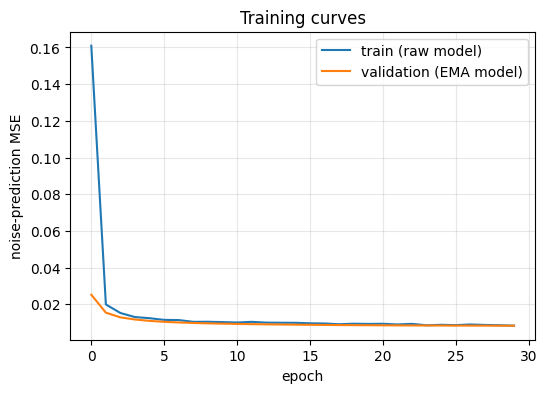

Loaded best checkpoint from epoch 30 (val loss 0.0083)


In [11]:
plt.figure(figsize=(6, 4))
plt.plot(history["train_loss"], label="train (raw model)")
plt.plot(history["val_loss"],   label="validation (EMA model)")
plt.xlabel("epoch"); plt.ylabel("noise-prediction MSE"); plt.legend(); plt.grid(alpha=0.3)
plt.title("Training curves")
plt.show()

ckpt = torch.load(CKPT_PATH, map_location=device)
best_model = UNet().to(device)
best_model.load_state_dict(ckpt["ema"])
best_model.eval()
print(f"Loaded best checkpoint from epoch {ckpt['epoch']} (val loss {ckpt['val_loss']:.4f})")

## 5. Quantitative evaluation on the held-out test split
Metrics are computed on images in [0, 1] and averaged per image:

| Metric | Meaning | Better |
|---|---|---|
| PSNR (dB) | pixel-level fidelity | higher |
| SSIM | structural similarity | higher |
| MSE | mean squared pixel error | lower |

**Baseline:** plain **bicubic interpolation** (the LR conditioning image itself). The diffusion model has to beat this to justify its cost.

In [12]:
def to01(x):
    return (x.clamp(-1, 1) + 1) / 2

def mse_per_image(a, b):
    return ((a - b) ** 2).mean(dim=(1, 2, 3))

def psnr_per_image(a, b):
    return 10 * torch.log10(1.0 / mse_per_image(a, b).clamp_min(1e-10))

def _gaussian_window(size=11, sigma=1.5, ch=3, dev="cpu"):
    coords = torch.arange(size, dtype=torch.float32, device=dev) - size // 2
    g = torch.exp(-coords ** 2 / (2 * sigma ** 2))
    g = g / g.sum()
    return (g[:, None] * g[None, :]).expand(ch, 1, size, size).contiguous()

def ssim_per_image(x, y, size=11, sigma=1.5):
    ch  = x.shape[1]
    w   = _gaussian_window(size, sigma, ch, x.device)
    pad = size // 2
    mu_x, mu_y = F.conv2d(x, w, padding=pad, groups=ch), F.conv2d(y, w, padding=pad, groups=ch)
    sxx = F.conv2d(x * x, w, padding=pad, groups=ch) - mu_x ** 2
    syy = F.conv2d(y * y, w, padding=pad, groups=ch) - mu_y ** 2
    sxy = F.conv2d(x * y, w, padding=pad, groups=ch) - mu_x * mu_y
    C1, C2 = 0.01 ** 2, 0.03 ** 2
    ssim_map = ((2 * mu_x * mu_y + C1) * (2 * sxy + C2)) / ((mu_x ** 2 + mu_y ** 2 + C1) * (sxx + syy + C2))
    return ssim_map.mean(dim=(1, 2, 3))


@torch.no_grad()
def evaluate_sr(model, diffusion, dataset, n=N_EVAL, batch_size=64, seed=SEED):
    torch.manual_seed(seed)
    idx = np.random.RandomState(seed).permutation(len(dataset))
    if n is not None:
        idx = idx[:n]

    rows = []
    for s in tqdm(range(0, len(idx), batch_size), desc="Evaluating"):
        batch  = [dataset[int(i)] for i in idx[s:s + batch_size]]
        lr     = torch.stack([b["lr"] for b in batch]).to(device)
        hr     = torch.stack([b["hr"] for b in batch]).to(device)
        labels = [CLASSES[b["label"]] for b in batch]

        sr = diffusion.sample(model, lr)
        hr01 = to01(hr)
        for name, pred in (("Bicubic (baseline)", to01(lr)), ("Diffusion SR", to01(sr))):
            mse, psnr, ssim = mse_per_image(pred, hr01), psnr_per_image(pred, hr01), ssim_per_image(pred, hr01)
            for j in range(len(batch)):
                rows.append({"method": name, "class": labels[j],
                             "psnr": psnr[j].item(), "ssim": ssim[j].item(), "mse": mse[j].item()})
    return pd.DataFrame(rows)


results = evaluate_sr(best_model, diffusion, test_ds)
summary = results.groupby("method")[["psnr", "ssim", "mse"]].agg(["mean", "std"]).round(4)
print(f"Held-out test images evaluated: {len(results) // 2}")
display(summary)

Evaluating:   0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

Held-out test images evaluated: 256


psnr            ssim             mse        
                       mean     std    mean     std    mean     std
method                                                             
Bicubic (baseline)  32.4500  7.8065  0.8115  0.1368  0.0017  0.0024
Diffusion SR        31.8086  7.8619  0.7963  0.1576  0.0022  0.0033

In [13]:
# Per-class breakdown (PSNR, dB)
per_class = results.pivot_table(index="class", columns="method", values="psnr", aggfunc="mean").round(2)
per_class["gain (dB)"] = (per_class["Diffusion SR"] - per_class["Bicubic (baseline)"]).round(2)
display(per_class)

results.to_csv("sr_test_metrics.csv", index=False)

method,Bicubic (baseline),Diffusion SR,gain (dB)
class,,,
AnnualCrop,30.92,33.38,2.46
Forest,40.19,39.01,-1.18
HerbaceousVegetation,32.21,30.63,-1.58
Highway,27.87,27.81,-0.06
Industrial,21.47,20.43,-1.04
Pasture,35.02,34.24,-0.78
PermanentCrop,27.26,25.80,-1.46
Residential,25.51,23.47,-2.04
River,31.65,31.70,0.05


### How to read the results
* If **Diffusion SR > Bicubic** on PSNR/SSIM, the model learned something beyond interpolation for this degradation.
* If it is **roughly equal or lower**, that is a legitimate result and should be reported as is: diffusion models are trained to produce *sharp, plausible* detail (sampled from a distribution), which is not what PSNR/SSIM reward, so they can score lower than smooth bicubic output even when they look better. Perceptual metrics (e.g. LPIPS) would be the natural next addition.
* Don't compare numbers with published benchmarks - this is a small 64x64 dataset with a synthetic degradation and a short training run.

## 6. Qualitative demo: one **test** image per class

  0%|          | 0/500 [00:00<?, ?it/s]

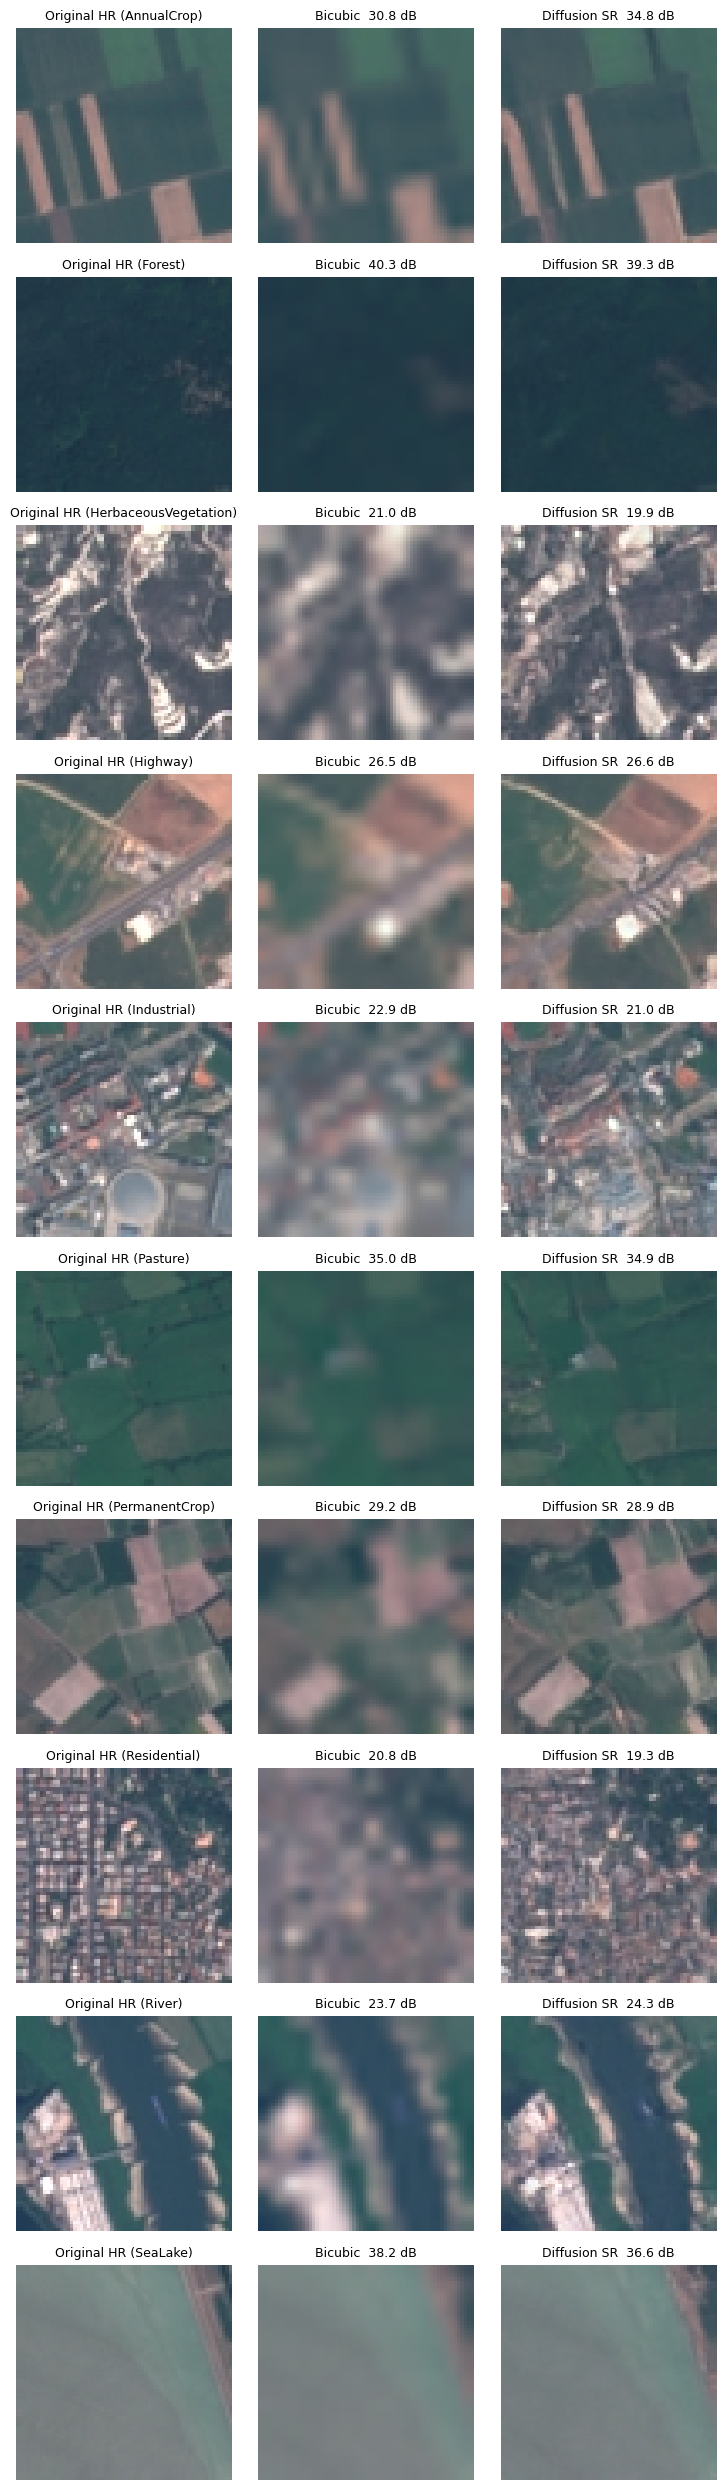

In [14]:
torch.manual_seed(SEED)
demo = {}
for i in range(len(test_ds)):                       # first test image of each class
    label = test_ds.items[i][1]
    if label not in demo:
        demo[label] = i
    if len(demo) == len(CLASSES):
        break

demo_idx = [demo[k] for k in sorted(demo)]
batch = [test_ds[i] for i in demo_idx]
lr = torch.stack([b["lr"] for b in batch]).to(device)
hr = torch.stack([b["hr"] for b in batch]).to(device)
sr = diffusion.sample(best_model, lr)

hr01, lr01, sr01 = to01(hr), to01(lr), to01(sr)
psnr_bic, psnr_sr = psnr_per_image(lr01, hr01), psnr_per_image(sr01, hr01)

n = len(batch)
fig, axes = plt.subplots(n, 3, figsize=(7.5, 2.5 * n))
for r in range(n):
    name = CLASSES[batch[r]["label"]]
    panels = [(hr01[r], f"Original HR ({name})"),
              (lr01[r], f"Bicubic  {psnr_bic[r]:.1f} dB"),
              (sr01[r], f"Diffusion SR  {psnr_sr[r]:.1f} dB")]
    for c, (img, title) in enumerate(panels):
        axes[r, c].imshow(img.permute(1, 2, 0).cpu().numpy())
        axes[r, c].set_title(title, fontsize=9)
        axes[r, c].axis("off")
plt.tight_layout()
plt.show()